# BÀI 4: XÂY DỰNG MÔ HÌNH MLP CHO DỮ LIỆU ẢNH 




# Khởi tạo dữ liệu Fashion-MNIST và huấn luyện sẵn **Mô hình mẫu gốc** làm chuẩn so sánh trực tiếp cho tất cả các bài tập bên dưới.


In [1]:
import os
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

reset_seed(SEED)

# Tải và chuẩn hóa dữ liệu Fashion-MNIST
fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

VAL_SIZE = 10_000
X_val = X_train_full[-VAL_SIZE:].astype("float32") / 255.0
y_val = y_train_full[-VAL_SIZE:]
X_train = X_train_full[:-VAL_SIZE].astype("float32") / 255.0
y_train = y_train_full[:-VAL_SIZE]
X_test = X_test.astype("float32") / 255.0

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

def make_datasets(batch_size=64):
    train_ds = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(buffer_size=len(X_train), seed=SEED)
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )
    test_ds = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )
    return train_ds, val_ds, test_ds

BATCH_SIZE = 64
train_ds, val_ds, test_ds = make_datasets(BATCH_SIZE)

# Huấn luyện Mô hình mẫu gốc (Baseline) để làm chuẩn so sánh cho mọi bài tập
reset_seed(SEED)
base_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
base_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)
base_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
base_history = base_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=base_callbacks,
    verbose=0
)
base_time = time.time() - t0
_, base_test_acc = base_model.evaluate(test_ds, verbose=0)

BASE_STATS = {
    "params": base_model.count_params(),
    "time": round(base_time, 2),
    "epochs": len(base_history.history["loss"]),
    "val_acc": round(max(base_history.history["val_accuracy"]), 4),
    "val_loss": round(min(base_history.history["val_loss"]), 4),
    "train_acc_last": round(base_history.history["accuracy"][-1], 4),
    "val_acc_last": round(base_history.history["val_accuracy"][-1], 4),
    "test_acc": round(base_test_acc, 4),
    "history": base_history.history
}

display(pd.DataFrame([{
    "Mô hình": "Mô hình mẫu gốc (256 -> 128, lr=1e-3, bs=64)",
    "Số parameter": BASE_STATS["params"],
    "Thời gian train (s)": BASE_STATS["time"],
    "Validation accuracy": BASE_STATS["val_acc"],
    "Test accuracy": BASE_STATS["test_acc"]
}]))


,Mô hình,Số parameter,Thời gian train (s),Validation accuracy,Test accuracy
0,"Mô hình mẫu gốc (256 -> 128, lr=1e-3, bs=64)",235146,25.63,0.891,0.8844


# BÀI 1. THAY ĐỔI KIẾN TRÚC

So sánh từng kiến trúc (`1 hidden layer`, `2 hidden layers`, `3 hidden layers`) trực tiếp với **Mô hình mẫu gốc** qua bảng thông số và biểu đồ đối chiếu.


## Trường hợp 1.1: 1 hidden layer (128)


,Mô hình,Số parameter,Thời gian train (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (2 layers),235146,25.63,0.891,0.8844,0.000
1,1 hidden layer (128),101770,13.48,0.887,0.8774,-0.007


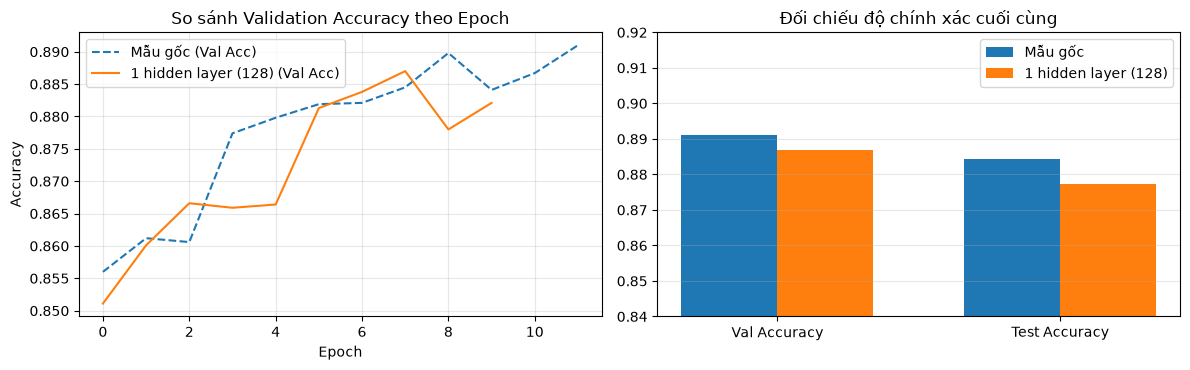

In [2]:
reset_seed(SEED)

model_b1_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_b1_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_b1_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_b1_1 = model_b1_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_b1_1,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_b1_1.evaluate(test_ds, verbose=0)

val_acc = round(max(history_b1_1.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

# Bảng so sánh trực tiếp với Mô hình mẫu gốc
df_comp = pd.DataFrame([
    {
        "Mô hình": "Mô hình mẫu gốc (2 layers)",
        "Số parameter": BASE_STATS["params"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Mô hình": "1 hidden layer (128)",
        "Số parameter": model_b1_1.count_params(),
        "Thời gian train (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

# Biểu đồ so sánh trực quan
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc (Val Acc)")
axes[0].plot(history_b1_1.history["val_accuracy"], label="1 hidden layer (128) (Val Acc)")
axes[0].set_title("So sánh Validation Accuracy theo Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

metrics_names = ["Val Accuracy", "Test Accuracy"]
x_pos = np.arange(len(metrics_names))
axes[1].bar(x_pos - 0.17, [BASE_STATS["val_acc"], BASE_STATS["test_acc"]], width=0.34, label="Mẫu gốc")
axes[1].bar(x_pos + 0.17, [val_acc, test_acc], width=0.34, label="1 hidden layer (128)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names)
axes[1].set_ylim(0.84, 0.92)
axes[1].set_title("Đối chiếu độ chính xác cuối cùng")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 1.2: 2 hidden layers (256 -> 128)


,Mô hình,Số parameter,Thời gian train (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (2 layers),235146,25.63,0.8910,0.8844,0.0000
1,2 hidden layers (256 -> 128),235146,48.70,0.8922,0.8861,0.0017


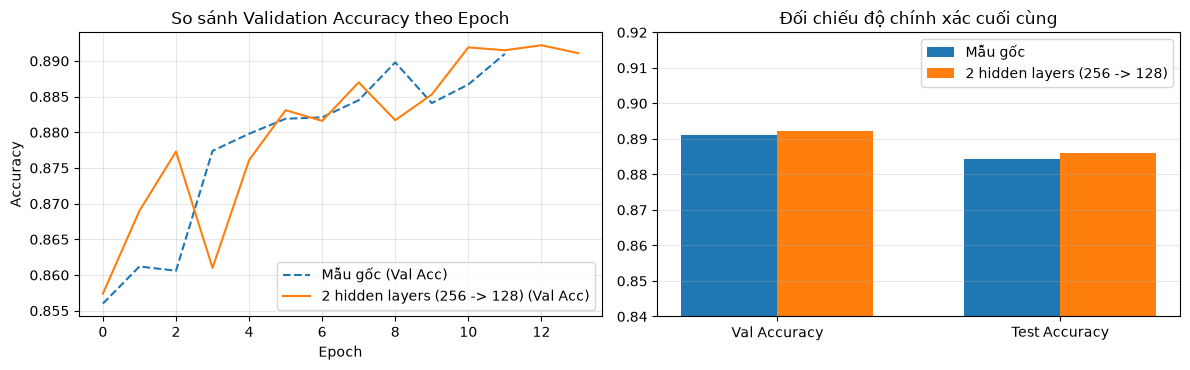

In [3]:
reset_seed(SEED)

model_b1_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_b1_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_b1_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_b1_2 = model_b1_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_b1_2,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_b1_2.evaluate(test_ds, verbose=0)

val_acc = round(max(history_b1_2.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

# Bảng so sánh trực tiếp với Mô hình mẫu gốc
df_comp = pd.DataFrame([
    {
        "Mô hình": "Mô hình mẫu gốc (2 layers)",
        "Số parameter": BASE_STATS["params"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Mô hình": "2 hidden layers (256 -> 128)",
        "Số parameter": model_b1_2.count_params(),
        "Thời gian train (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

# Biểu đồ so sánh trực quan
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc (Val Acc)")
axes[0].plot(history_b1_2.history["val_accuracy"], label="2 hidden layers (256 -> 128) (Val Acc)")
axes[0].set_title("So sánh Validation Accuracy theo Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

metrics_names = ["Val Accuracy", "Test Accuracy"]
x_pos = np.arange(len(metrics_names))
axes[1].bar(x_pos - 0.17, [BASE_STATS["val_acc"], BASE_STATS["test_acc"]], width=0.34, label="Mẫu gốc")
axes[1].bar(x_pos + 0.17, [val_acc, test_acc], width=0.34, label="2 hidden layers (256 -> 128)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names)
axes[1].set_ylim(0.84, 0.92)
axes[1].set_title("Đối chiếu độ chính xác cuối cùng")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 1.3: 3 hidden layers (256 -> 128 -> 64)


,Mô hình,Số parameter,Thời gian train (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (2 layers),235146,25.63,0.8910,0.8844,0.0000
1,3 hidden layers (256 -> 128 -> 64),242762,23.40,0.8899,0.8836,-0.0008


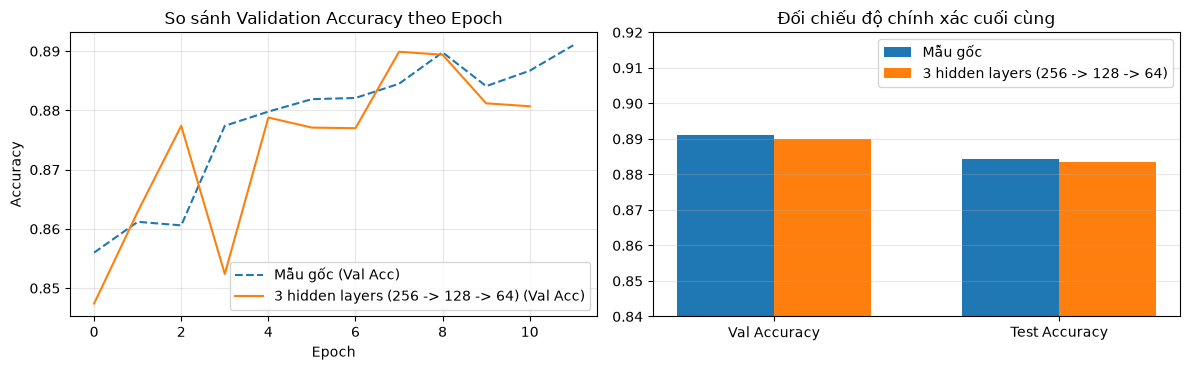

In [4]:
reset_seed(SEED)

model_b1_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_b1_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_b1_3 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_b1_3 = model_b1_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_b1_3,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_b1_3.evaluate(test_ds, verbose=0)

val_acc = round(max(history_b1_3.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

# Bảng so sánh trực tiếp với Mô hình mẫu gốc
df_comp = pd.DataFrame([
    {
        "Mô hình": "Mô hình mẫu gốc (2 layers)",
        "Số parameter": BASE_STATS["params"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Mô hình": "3 hidden layers (256 -> 128 -> 64)",
        "Số parameter": model_b1_3.count_params(),
        "Thời gian train (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

# Biểu đồ so sánh trực quan
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc (Val Acc)")
axes[0].plot(history_b1_3.history["val_accuracy"], label="3 hidden layers (256 -> 128 -> 64) (Val Acc)")
axes[0].set_title("So sánh Validation Accuracy theo Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

metrics_names = ["Val Accuracy", "Test Accuracy"]
x_pos = np.arange(len(metrics_names))
axes[1].bar(x_pos - 0.17, [BASE_STATS["val_acc"], BASE_STATS["test_acc"]], width=0.34, label="Mẫu gốc")
axes[1].bar(x_pos + 0.17, [val_acc, test_acc], width=0.34, label="3 hidden layers (256 -> 128 -> 64)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names)
axes[1].set_ylim(0.84, 0.92)
axes[1].set_title("Đối chiếu độ chính xác cuối cùng")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# BÀI 2. THỬ LEARNING RATE

So sánh từng giá trị `learning_rate` (`1e-2`, `1e-3`, `1e-4`) trực tiếp với **Mô hình mẫu gốc** (`lr = 1e-3`) qua bảng số liệu và đường cong learning curve đối chiếu.


## Trường hợp 2.1: Learning rate = `1e-2`


,Cấu hình,Số epoch chạy,Thời gian train (s),Val loss thấp nhất,Val accuracy cao nhất,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (lr = 1e-3),12,25.63,0.3065,0.891,0.8844,0.0000
1,Thử nghiệm (lr = 1e-2),6,12.44,0.3757,0.863,0.8581,-0.0263


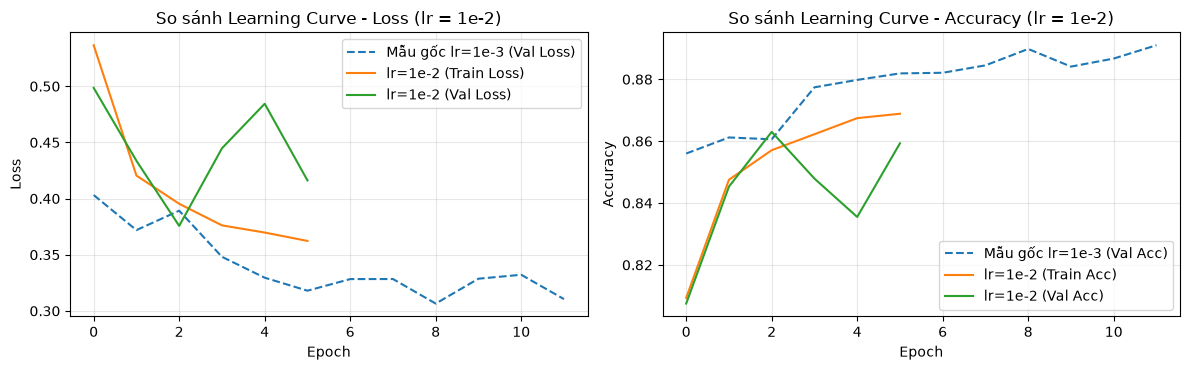

In [5]:
reset_seed(SEED)

model_lr_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_lr_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-2),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_lr_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_lr_1 = model_lr_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_lr_1,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_lr_1.evaluate(test_ds, verbose=0)

val_acc = round(max(history_lr_1.history["val_accuracy"]), 4)
val_loss = round(min(history_lr_1.history["val_loss"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (lr = 1e-3)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Val loss thấp nhất": BASE_STATS["val_loss"],
        "Val accuracy cao nhất": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (lr = 1e-2)",
        "Số epoch chạy": len(history_lr_1.history["loss"]),
        "Thời gian train (s)": round(train_time, 2),
        "Val loss thấp nhất": val_loss,
        "Val accuracy cao nhất": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc lr=1e-3 (Val Loss)")
axes[0].plot(history_lr_1.history["loss"], label="lr=1e-2 (Train Loss)")
axes[0].plot(history_lr_1.history["val_loss"], label="lr=1e-2 (Val Loss)")
axes[0].set_title("So sánh Learning Curve - Loss (lr = 1e-2)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc lr=1e-3 (Val Acc)")
axes[1].plot(history_lr_1.history["accuracy"], label="lr=1e-2 (Train Acc)")
axes[1].plot(history_lr_1.history["val_accuracy"], label="lr=1e-2 (Val Acc)")
axes[1].set_title("So sánh Learning Curve - Accuracy (lr = 1e-2)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 2.2: Learning rate = `1e-3`


,Cấu hình,Số epoch chạy,Thời gian train (s),Val loss thấp nhất,Val accuracy cao nhất,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (lr = 1e-3),12,25.63,0.3065,0.8910,0.8844,0.0000
1,Thử nghiệm (lr = 1e-3),12,24.95,0.3101,0.8889,0.8799,-0.0045


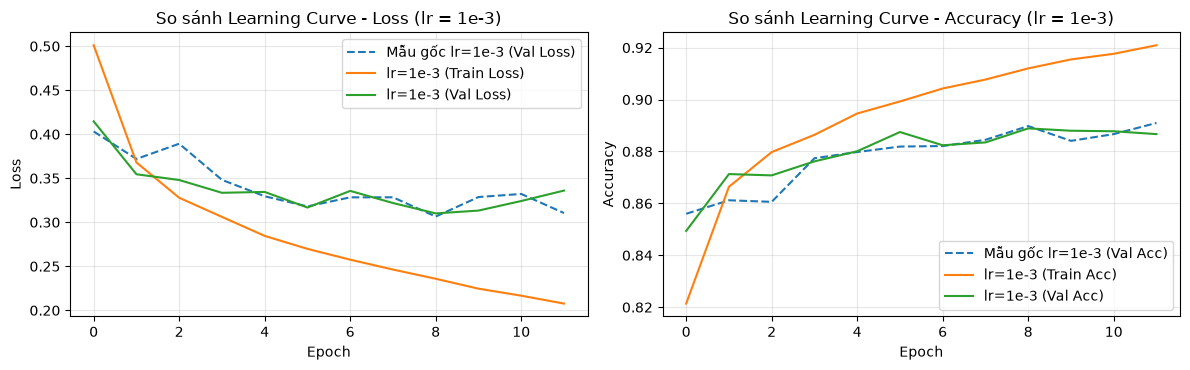

In [6]:
reset_seed(SEED)

model_lr_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_lr_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_lr_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_lr_2 = model_lr_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_lr_2,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_lr_2.evaluate(test_ds, verbose=0)

val_acc = round(max(history_lr_2.history["val_accuracy"]), 4)
val_loss = round(min(history_lr_2.history["val_loss"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (lr = 1e-3)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Val loss thấp nhất": BASE_STATS["val_loss"],
        "Val accuracy cao nhất": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (lr = 1e-3)",
        "Số epoch chạy": len(history_lr_2.history["loss"]),
        "Thời gian train (s)": round(train_time, 2),
        "Val loss thấp nhất": val_loss,
        "Val accuracy cao nhất": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc lr=1e-3 (Val Loss)")
axes[0].plot(history_lr_2.history["loss"], label="lr=1e-3 (Train Loss)")
axes[0].plot(history_lr_2.history["val_loss"], label="lr=1e-3 (Val Loss)")
axes[0].set_title("So sánh Learning Curve - Loss (lr = 1e-3)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc lr=1e-3 (Val Acc)")
axes[1].plot(history_lr_2.history["accuracy"], label="lr=1e-3 (Train Acc)")
axes[1].plot(history_lr_2.history["val_accuracy"], label="lr=1e-3 (Val Acc)")
axes[1].set_title("So sánh Learning Curve - Accuracy (lr = 1e-3)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 2.3: Learning rate = `1e-4`


,Cấu hình,Số epoch chạy,Thời gian train (s),Val loss thấp nhất,Val accuracy cao nhất,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (lr = 1e-3),12,25.63,0.3065,0.8910,0.8844,0.0000
1,Thử nghiệm (lr = 1e-4),26,115.53,0.3023,0.8912,0.8860,0.0016


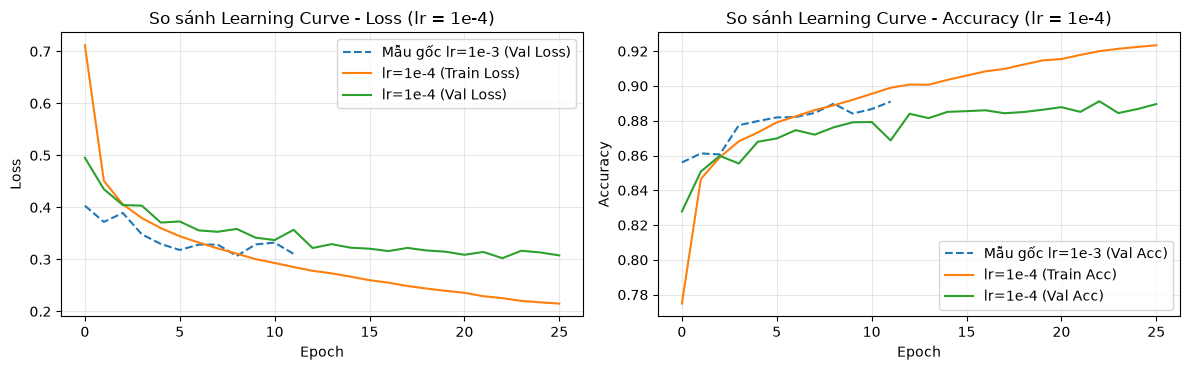

In [7]:
reset_seed(SEED)

model_lr_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_lr_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_lr_3 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_lr_3 = model_lr_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_lr_3,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_lr_3.evaluate(test_ds, verbose=0)

val_acc = round(max(history_lr_3.history["val_accuracy"]), 4)
val_loss = round(min(history_lr_3.history["val_loss"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (lr = 1e-3)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Thời gian train (s)": BASE_STATS["time"],
        "Val loss thấp nhất": BASE_STATS["val_loss"],
        "Val accuracy cao nhất": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (lr = 1e-4)",
        "Số epoch chạy": len(history_lr_3.history["loss"]),
        "Thời gian train (s)": round(train_time, 2),
        "Val loss thấp nhất": val_loss,
        "Val accuracy cao nhất": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc lr=1e-3 (Val Loss)")
axes[0].plot(history_lr_3.history["loss"], label="lr=1e-4 (Train Loss)")
axes[0].plot(history_lr_3.history["val_loss"], label="lr=1e-4 (Val Loss)")
axes[0].set_title("So sánh Learning Curve - Loss (lr = 1e-4)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc lr=1e-3 (Val Acc)")
axes[1].plot(history_lr_3.history["accuracy"], label="lr=1e-4 (Train Acc)")
axes[1].plot(history_lr_3.history["val_accuracy"], label="lr=1e-4 (Val Acc)")
axes[1].set_title("So sánh Learning Curve - Accuracy (lr = 1e-4)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# BÀI 3. THỬ BATCH SIZE

So sánh từng kích thước `batch_size` (`32`, `128`, `512`) trực tiếp với **Mô hình mẫu gốc** (`batch_size = 64`) về tốc độ huấn luyện và độ chính xác.


## Trường hợp 3.1: Batch size = `32`


,Cấu hình,Số epoch chạy,Tổng thời gian (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (batch_size = 64),12,25.63,0.8910,0.8844,0.0000
1,Thử nghiệm (batch_size = 32),12,42.18,0.8883,0.8859,0.0015


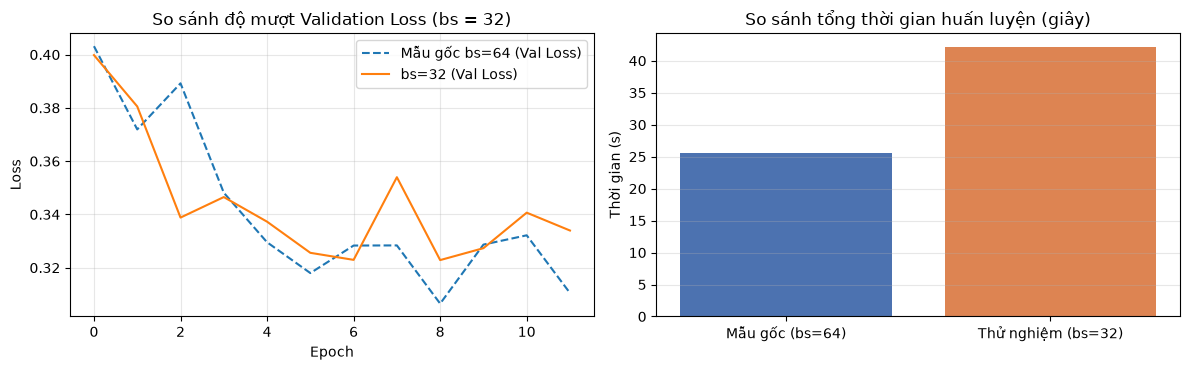

In [8]:
reset_seed(SEED)

train_ds_bs, val_ds_bs, test_ds_bs = make_datasets(batch_size=32)

model_bs_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_bs_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_bs_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_bs_1 = model_bs_1.fit(
    train_ds_bs,
    validation_data=val_ds_bs,
    epochs=40,
    callbacks=callbacks_bs_1,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_bs_1.evaluate(test_ds_bs, verbose=0)

val_acc = round(max(history_bs_1.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (batch_size = 64)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Tổng thời gian (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (batch_size = 32)",
        "Số epoch chạy": len(history_bs_1.history["loss"]),
        "Tổng thời gian (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc bs=64 (Val Loss)")
axes[0].plot(history_bs_1.history["val_loss"], label="bs=32 (Val Loss)")
axes[0].set_title("So sánh độ mượt Validation Loss (bs = 32)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(["Mẫu gốc (bs=64)", "Thử nghiệm (bs=32)"], [BASE_STATS["time"], round(train_time, 2)], color=["#4C72B0", "#DD8452"])
axes[1].set_title("So sánh tổng thời gian huấn luyện (giây)")
axes[1].set_ylabel("Thời gian (s)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 3.2: Batch size = `128`


,Cấu hình,Số epoch chạy,Tổng thời gian (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (batch_size = 64),12,25.63,0.8910,0.8844,0.0000
1,Thử nghiệm (batch_size = 128),12,38.09,0.8905,0.8838,-0.0006


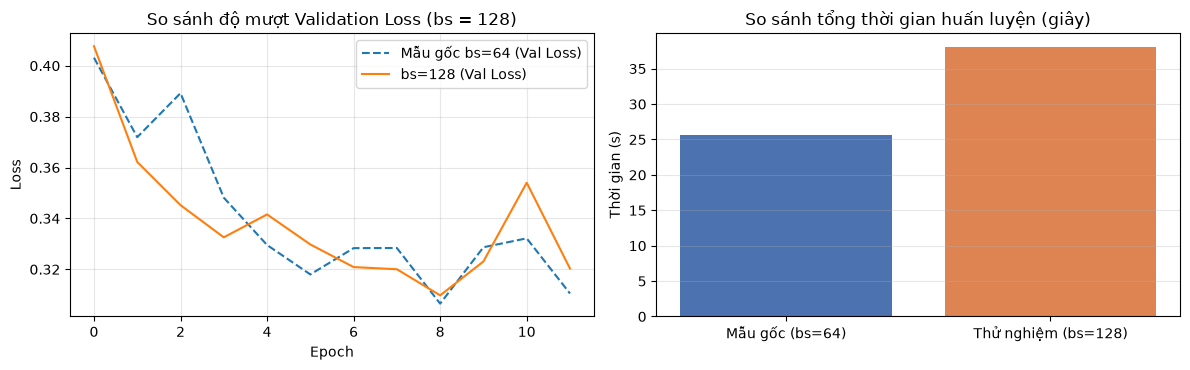

In [9]:
reset_seed(SEED)

train_ds_bs, val_ds_bs, test_ds_bs = make_datasets(batch_size=128)

model_bs_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_bs_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_bs_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_bs_2 = model_bs_2.fit(
    train_ds_bs,
    validation_data=val_ds_bs,
    epochs=40,
    callbacks=callbacks_bs_2,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_bs_2.evaluate(test_ds_bs, verbose=0)

val_acc = round(max(history_bs_2.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (batch_size = 64)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Tổng thời gian (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (batch_size = 128)",
        "Số epoch chạy": len(history_bs_2.history["loss"]),
        "Tổng thời gian (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc bs=64 (Val Loss)")
axes[0].plot(history_bs_2.history["val_loss"], label="bs=128 (Val Loss)")
axes[0].set_title("So sánh độ mượt Validation Loss (bs = 128)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(["Mẫu gốc (bs=64)", "Thử nghiệm (bs=128)"], [BASE_STATS["time"], round(train_time, 2)], color=["#4C72B0", "#DD8452"])
axes[1].set_title("So sánh tổng thời gian huấn luyện (giây)")
axes[1].set_ylabel("Thời gian (s)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 3.3: Batch size = `512`


,Cấu hình,Số epoch chạy,Tổng thời gian (s),Validation accuracy,Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (batch_size = 64),12,25.63,0.8910,0.8844,0.0000
1,Thử nghiệm (batch_size = 512),17,37.86,0.8902,0.8876,0.0032


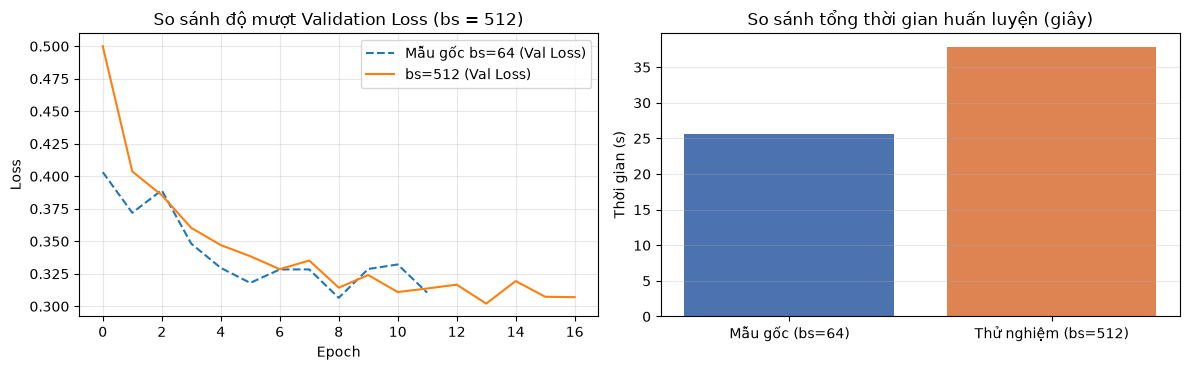

In [10]:
reset_seed(SEED)

train_ds_bs, val_ds_bs, test_ds_bs = make_datasets(batch_size=512)

model_bs_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_bs_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_bs_3 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_bs_3 = model_bs_3.fit(
    train_ds_bs,
    validation_data=val_ds_bs,
    epochs=40,
    callbacks=callbacks_bs_3,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_bs_3.evaluate(test_ds_bs, verbose=0)

val_acc = round(max(history_bs_3.history["val_accuracy"]), 4)
test_acc = round(test_acc, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (batch_size = 64)",
        "Số epoch chạy": BASE_STATS["epochs"],
        "Tổng thời gian (s)": BASE_STATS["time"],
        "Validation accuracy": BASE_STATS["val_acc"],
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thử nghiệm (batch_size = 512)",
        "Số epoch chạy": len(history_bs_3.history["loss"]),
        "Tổng thời gian (s)": round(train_time, 2),
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_loss"], "--", label="Mẫu gốc bs=64 (Val Loss)")
axes[0].plot(history_bs_3.history["val_loss"], label="bs=512 (Val Loss)")
axes[0].set_title("So sánh độ mượt Validation Loss (bs = 512)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(["Mẫu gốc (bs=64)", "Thử nghiệm (bs=512)"], [BASE_STATS["time"], round(train_time, 2)], color=["#4C72B0", "#DD8452"])
axes[1].set_title("So sánh tổng thời gian huấn luyện (giây)")
axes[1].set_ylabel("Thời gian (s)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# BÀI 4. THÊM DROPOUT

Thêm `Dropout(0.3)` vào giữa các Dense layer và so sánh trực tiếp khoảng cách `Train - Validation Accuracy` với **Mô hình mẫu gốc**.


,Cấu hình,Train Acc cuối,Val Acc cuối,Khoảng cách Overfit (Train - Val),Test accuracy
0,Mô hình mẫu gốc (Không Dropout),0.9210,0.8910,0.0300,0.8844
1,Thêm Dropout(0.3),0.8968,0.8866,0.0102,0.8855


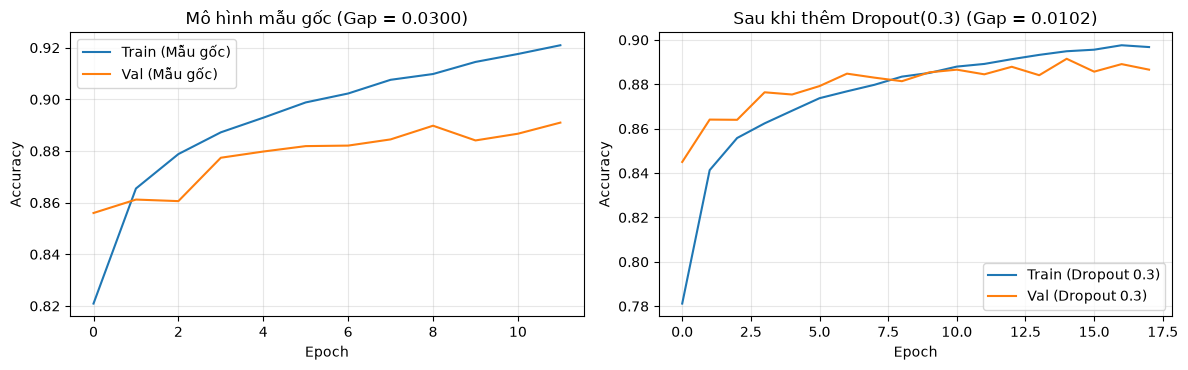

In [11]:
reset_seed(SEED)

model_drop = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_drop.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_drop = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_drop = model_drop.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_drop,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_drop.evaluate(test_ds, verbose=0)

tr_last = round(history_drop.history["accuracy"][-1], 4)
va_last = round(history_drop.history["val_accuracy"][-1], 4)
test_acc = round(test_acc, 4)

base_gap = round(BASE_STATS["train_acc_last"] - BASE_STATS["val_acc_last"], 4)
drop_gap = round(tr_last - va_last, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (Không Dropout)",
        "Train Acc cuối": BASE_STATS["train_acc_last"],
        "Val Acc cuối": BASE_STATS["val_acc_last"],
        "Khoảng cách Overfit (Train - Val)": base_gap,
        "Test accuracy": BASE_STATS["test_acc"]
    },
    {
        "Cấu hình": "Thêm Dropout(0.3)",
        "Train Acc cuối": tr_last,
        "Val Acc cuối": va_last,
        "Khoảng cách Overfit (Train - Val)": drop_gap,
        "Test accuracy": test_acc
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["accuracy"], label="Train (Mẫu gốc)")
axes[0].plot(BASE_STATS["history"]["val_accuracy"], label="Val (Mẫu gốc)")
axes[0].set_title(f"Mô hình mẫu gốc (Gap = {base_gap:.4f})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_drop.history["accuracy"], label="Train (Dropout 0.3)")
axes[1].plot(history_drop.history["val_accuracy"], label="Val (Dropout 0.3)")
axes[1].set_title(f"Sau khi thêm Dropout(0.3) (Gap = {drop_gap:.4f})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# BÀI 5. THÊM L2 REGULARIZATION

Áp dụng `kernel_regularizer=tf.keras.regularizers.l2(...)` với các hệ số phạt (`1e-4`, `1e-3`) và so sánh trực tiếp với **Mô hình mẫu gốc**.


## Trường hợp 5.1: L2 regularization với hệ số `1e-4`


,Cấu hình,Train Acc cuối,Val Acc cuối,Khoảng cách Overfit (Train - Val),Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (Không L2),0.9210,0.8910,0.0300,0.8844,0.0000
1,Thêm L2 (1e-4),0.8991,0.8823,0.0168,0.8770,-0.0074


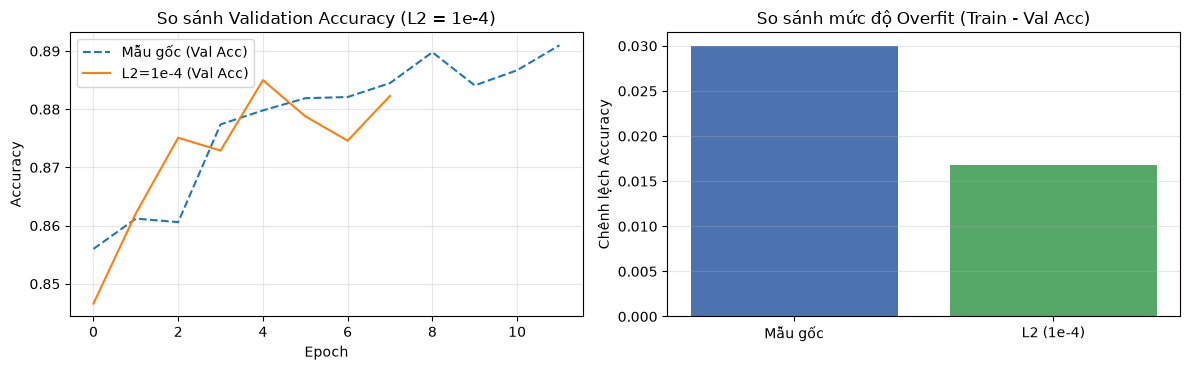

In [12]:
reset_seed(SEED)

model_l2_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),
    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_l2_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_l2_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_l2_1 = model_l2_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_l2_1,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_l2_1.evaluate(test_ds, verbose=0)

tr_last = round(history_l2_1.history["accuracy"][-1], 4)
va_last = round(history_l2_1.history["val_accuracy"][-1], 4)
test_acc = round(test_acc, 4)

base_gap = round(BASE_STATS["train_acc_last"] - BASE_STATS["val_acc_last"], 4)
l2_gap = round(tr_last - va_last, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (Không L2)",
        "Train Acc cuối": BASE_STATS["train_acc_last"],
        "Val Acc cuối": BASE_STATS["val_acc_last"],
        "Khoảng cách Overfit (Train - Val)": base_gap,
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thêm L2 (1e-4)",
        "Train Acc cuối": tr_last,
        "Val Acc cuối": va_last,
        "Khoảng cách Overfit (Train - Val)": l2_gap,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc (Val Acc)")
axes[0].plot(history_l2_1.history["val_accuracy"], label="L2=1e-4 (Val Acc)")
axes[0].set_title("So sánh Validation Accuracy (L2 = 1e-4)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(["Mẫu gốc", "L2 (1e-4)"], [base_gap, l2_gap], color=["#4C72B0", "#55A868"])
axes[1].set_title("So sánh mức độ Overfit (Train - Val Acc)")
axes[1].set_ylabel("Chênh lệch Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Trường hợp 5.2: L2 regularization với hệ số `1e-3`


,Cấu hình,Train Acc cuối,Val Acc cuối,Khoảng cách Overfit (Train - Val),Test accuracy,Chênh lệch Test Acc
0,Mô hình mẫu gốc (Không L2),0.9210,0.8910,0.0300,0.8844,0.0000
1,Thêm L2 (1e-3),0.8899,0.8774,0.0125,0.8698,-0.0146


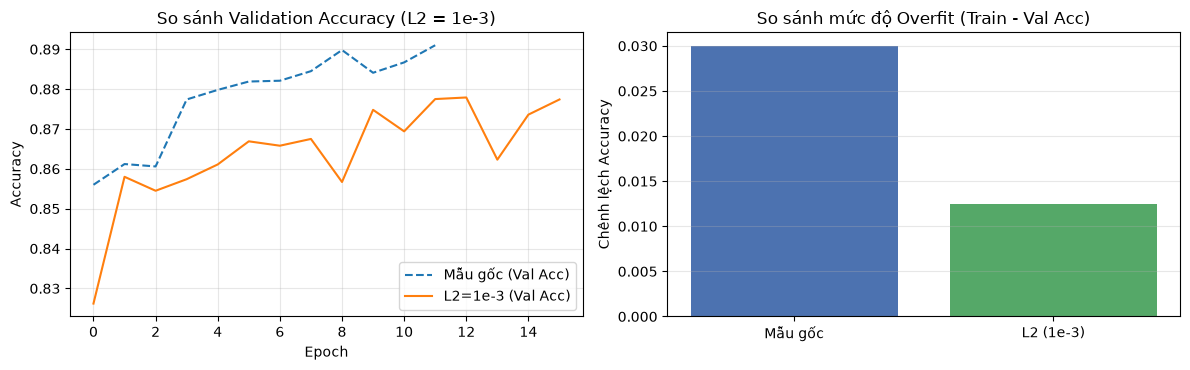

In [13]:
reset_seed(SEED)

model_l2_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-3)
    ),
    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-3)
    ),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_l2_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_l2_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

t0 = time.time()
history_l2_2 = model_l2_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_l2_2,
    verbose=0
)
train_time = time.time() - t0
_, test_acc = model_l2_2.evaluate(test_ds, verbose=0)

tr_last = round(history_l2_2.history["accuracy"][-1], 4)
va_last = round(history_l2_2.history["val_accuracy"][-1], 4)
test_acc = round(test_acc, 4)

base_gap = round(BASE_STATS["train_acc_last"] - BASE_STATS["val_acc_last"], 4)
l2_gap = round(tr_last - va_last, 4)

df_comp = pd.DataFrame([
    {
        "Cấu hình": "Mô hình mẫu gốc (Không L2)",
        "Train Acc cuối": BASE_STATS["train_acc_last"],
        "Val Acc cuối": BASE_STATS["val_acc_last"],
        "Khoảng cách Overfit (Train - Val)": base_gap,
        "Test accuracy": BASE_STATS["test_acc"],
        "Chênh lệch Test Acc": 0.0000
    },
    {
        "Cấu hình": "Thêm L2 (1e-3)",
        "Train Acc cuối": tr_last,
        "Val Acc cuối": va_last,
        "Khoảng cách Overfit (Train - Val)": l2_gap,
        "Test accuracy": test_acc,
        "Chênh lệch Test Acc": round(test_acc - BASE_STATS["test_acc"], 4)
    }
])
display(df_comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(BASE_STATS["history"]["val_accuracy"], "--", label="Mẫu gốc (Val Acc)")
axes[0].plot(history_l2_2.history["val_accuracy"], label="L2=1e-3 (Val Acc)")
axes[0].set_title("So sánh Validation Accuracy (L2 = 1e-3)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(["Mẫu gốc", "L2 (1e-3)"], [base_gap, l2_gap], color=["#4C72B0", "#55A868"])
axes[1].set_title("So sánh mức độ Overfit (Train - Val Acc)")
axes[1].set_ylabel("Chênh lệch Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# BÀI 6. PHÂN TÍCH LỖI (ERROR ANALYSIS)

Tìm **20 mẫu trên tập Test bị dự đoán sai với độ tự tin (confidence) cao nhất**, hiển thị bảng thống kê và lưới 20 ảnh thực tế để phân tích nguyên nhân.


,Thứ tự,Index ảnh,Nhãn thật,Nhãn dự đoán,Confidence (%)
0,1,6565,8 (Bag),7 (Sneaker),100.000000
1,2,4394,3 (Dress),8 (Bag),99.989998
2,3,3866,5 (Sandal),9 (Ankle boot),99.980003
3,4,5946,9 (Ankle boot),5 (Sandal),99.980003
4,5,5661,4 (Coat),8 (Bag),99.959999
5,6,787,1 (Trouser),3 (Dress),99.949997
6,7,5235,5 (Sandal),8 (Bag),99.949997
7,8,324,4 (Coat),6 (Shirt),99.949997
8,9,3531,0 (T-shirt/top),3 (Dress),99.949997
9,10,2856,6 (Shirt),0 (T-shirt/top),99.930000


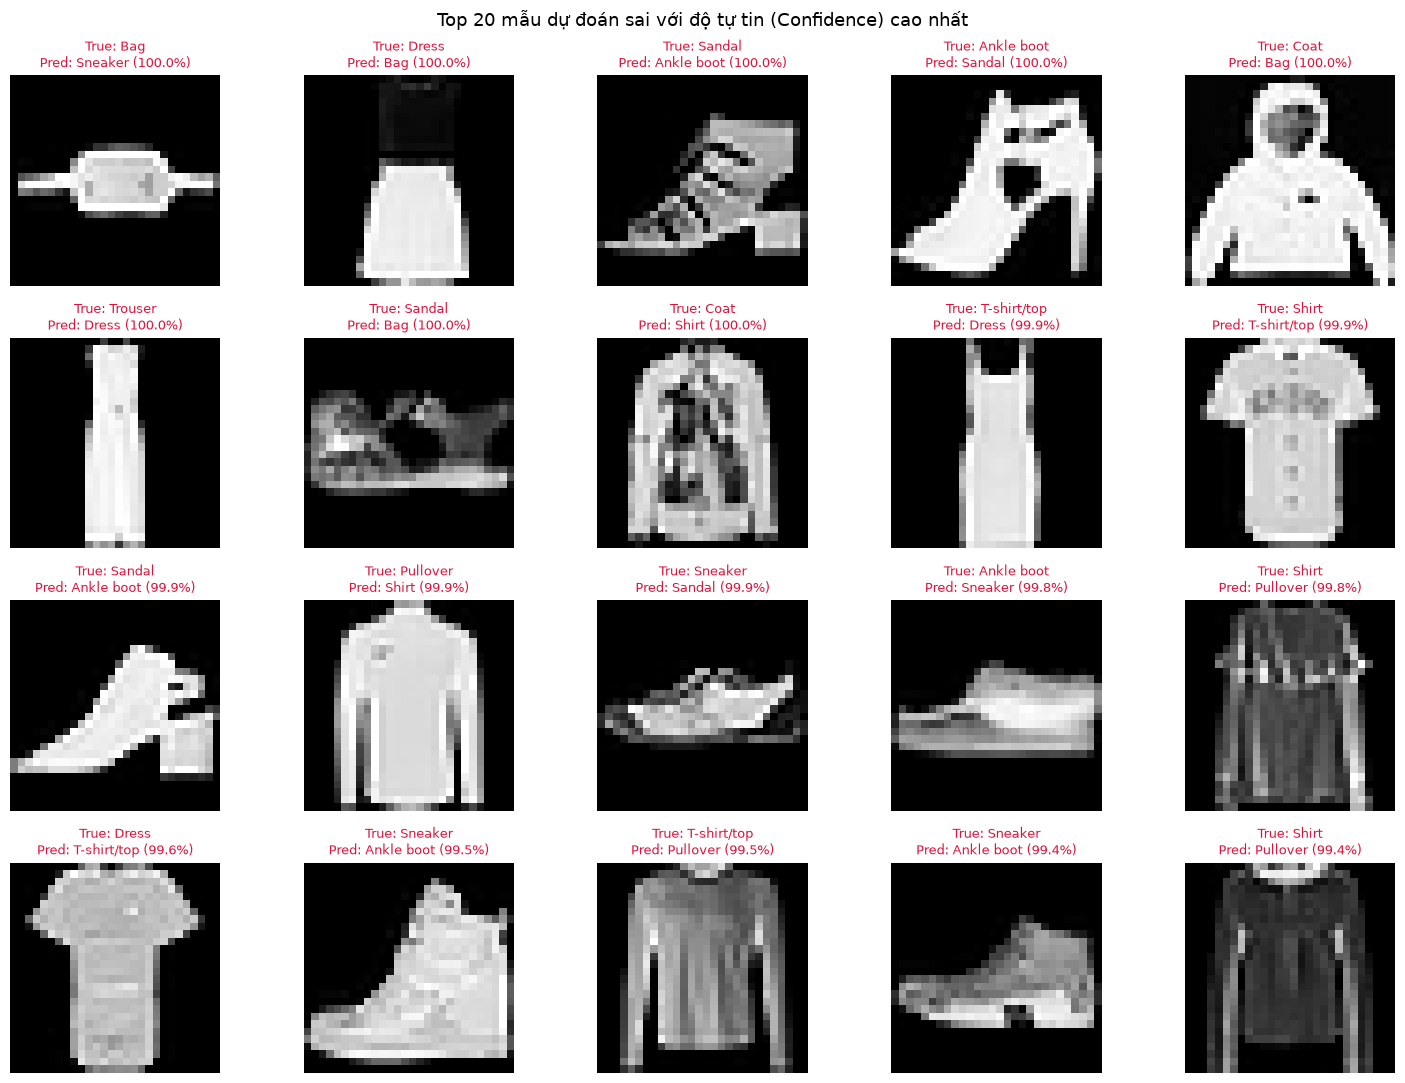

In [14]:
best_model = model_drop
y_prob_test = best_model.predict(X_test, verbose=0)
y_pred_test = np.argmax(y_prob_test, axis=1)
confidences = np.max(y_prob_test, axis=1)

wrong_idx = np.where(y_pred_test != y_test)[0]
wrong_confidences = confidences[wrong_idx]

top20_order = np.argsort(wrong_confidences)[::-1][:20]
top20_idx = wrong_idx[top20_order]

error_table = pd.DataFrame({
    "Thứ tự": np.arange(1, 21),
    "Index ảnh": top20_idx,
    "Nhãn thật": [f"{y_test[i]} ({class_names[y_test[i]]})" for i in top20_idx],
    "Nhãn dự đoán": [f"{y_pred_test[i]} ({class_names[y_pred_test[i]]})" for i in top20_idx],
    "Confidence (%)": (confidences[top20_idx] * 100).round(2)
})
display(error_table)

fig, axes = plt.subplots(4, 5, figsize=(15, 11))
for k, ax in enumerate(axes.ravel()):
    idx = top20_idx[k]
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred_test[idx]]} ({confidences[idx]*100:.1f}%)",
        fontsize=9,
        color="crimson"
    )
    ax.axis("off")

plt.suptitle("Top 20 mẫu dự đoán sai với độ tự tin (Confidence) cao nhất", fontsize=13)
plt.tight_layout()
plt.show()
